# Hidden unfairness: replicating fairness gerrymandering

This notebook walks through the replication of Kearns, Neel, Roth & Wu (2018) using the `subgroup_audit` package in `src/`. The heavy lifting (training ~40 models per dataset) is done by `scripts/run_experiments.py`; here we load its saved results and re-run the parts that are quick.

In [1]:
import sys, json
sys.path.insert(0, '../src')
import numpy as np, pandas as pd
from IPython.display import Image, display
from subgroup_audit import audit as A
R = {n: json.load(open(f'../results/{n}.json')) for n in ['communities', 'adult', 'diabetes']}

## 1. The idea in one toy example

Four cells of 400 true negatives each. Single attributes look perfectly fair; every intersection is off by 15 points.

In [2]:
rows = []
for sex in ['Male', 'Female']:
    for race in ['White', 'Black']:
        fpr = 0.4 if (sex == 'Male') == (race == 'Black') else 0.1
        rows += [{'sex': sex, 'race': race, 'y': 0, 'p': int(i < fpr * 400)} for i in range(400)]
toy = pd.DataFrame(rows)
res = A.audit(toy.y, toy.p, toy[['sex', 'race']], 'fpr', max_order=2)
pd.DataFrame(res['single_attribute'] + res['top_raw_gap'][:4])[['subgroup', 'rate', 'gap', 'weighted_gap']]

,subgroup,rate,gap,weighted_gap
0,race=Black,0.25,0.00,0.0000
1,race=White,0.25,0.00,0.0000
2,sex=Female,0.25,0.00,0.0000
3,sex=Male,0.25,0.00,0.0000
4,sex=Male & race=Black,0.40,0.15,0.0375
5,sex=Female & race=White,0.40,0.15,0.0375
6,sex=Male & race=White,0.10,-0.15,0.0375
7,sex=Female & race=Black,0.10,-0.15,0.0375


## 2. Baseline models: single attributes vs. intersections (test set)

In [3]:
def headline(name):
    out = []
    for k, m in R[name]['models'].items():
        out.append({'model': k, 'accuracy': m['overall']['accuracy'],
                    'worst single': f"{m['worst_single']['subgroup']} ({100*m['worst_single']['gap']:+.1f} pp)",
                    'worst intersection': f"{m['worst_intersection']['subgroup']} ({100*m['worst_intersection']['gap']:+.1f} pp, n={m['worst_intersection']['base_size']})",
                    'max weighted gap': m['max_weighted_gap'], 'train max weighted gap': m['train_max_weighted_gap']})
    return pd.DataFrame(out).round(4)
for n in R:
    print(n, R[n]['metric'].upper()); display(headline(n))

communities FPR


,model,accuracy,worst single,worst intersection,max weighted gap,train max weighted gap
0,logistic,0.8481,pct_white=low (+12.2 pp),pct_white=low & pct_asian=low & pct_age_65plus...,0.0307,0.0192
1,boosting,0.8631,pct_white=low (+14.5 pp),pct_white=low & pct_asian=low & pct_age_65plus...,0.0366,0.0160
2,marginal_fair,0.8134,pct_white=low (+8.3 pp),pct_white=low & pct_asian=low & pct_age_65plus...,0.0208,0.0073
3,subgroup_fair,0.8013,pct_white=low (+6.8 pp),pct_white=low & pct_asian=low & pct_age_65plus...,0.0171,0.0044
4,subgroup_fair_boosting,0.8066,pct_white=low (+7.4 pp),pct_white=low & pct_asian=low & pct_age_65plus...,0.0187,0.0048


adult FPR


,model,accuracy,worst single,worst intersection,max weighted gap,train max weighted gap
0,logistic,0.8493,age_band=60+ (+7.2 pp),sex=Male & race=White & age_band=60+ (+16.2 pp...,0.0148,0.0148
1,boosting,0.8619,race=Asian-PI (+6.2 pp),sex=Male & race=Asian-PI & age_band=45-59 (+21...,0.0129,0.0121
2,marginal_fair,0.8178,race=Other (-5.0 pp),sex=Male & race=Asian-PI & age_band=30-44 (+9....,0.0073,0.0063
3,subgroup_fair,0.8110,race=Asian-PI (+10.6 pp),sex=Male & race=Asian-PI & age_band=30-44 (+21...,0.0056,0.0046
4,subgroup_fair_boosting,0.8233,race=Asian-PI (+6.7 pp),sex=Male & race=Asian-PI & age_band=45-59 (+20...,0.0061,0.0055


diabetes FNR


,model,accuracy,worst single,worst intersection,max weighted gap,train max weighted gap
0,logistic,0.6782,age_band=<40 (+28.8 pp),"race=Black & age_band=<40 (+34.3 pp, n=33)",0.0027,0.0034
1,boosting,0.6597,age_band=<40 (+26.2 pp),sex=Female & race=White & age_band=<40 (+32.8 ...,0.0031,0.0037
2,marginal_fair,0.6736,age_band=<40 (+11.1 pp),"race=Black & age_band=<40 (+16.3 pp, n=33)",0.0007,0.0011
3,subgroup_fair,0.6731,age_band=<40 (+11.5 pp),sex=Female & race=White & age_band=<40 (+16.4 ...,0.0008,0.0010
4,subgroup_fair_boosting,0.6655,age_band=<40 (+24.2 pp),sex=Female & race=White & age_band=<40 (+32.4 ...,0.0013,0.0010


## 3. The gerrymandering effect

A model trained to be fair on each attribute separately, audited on intersections.

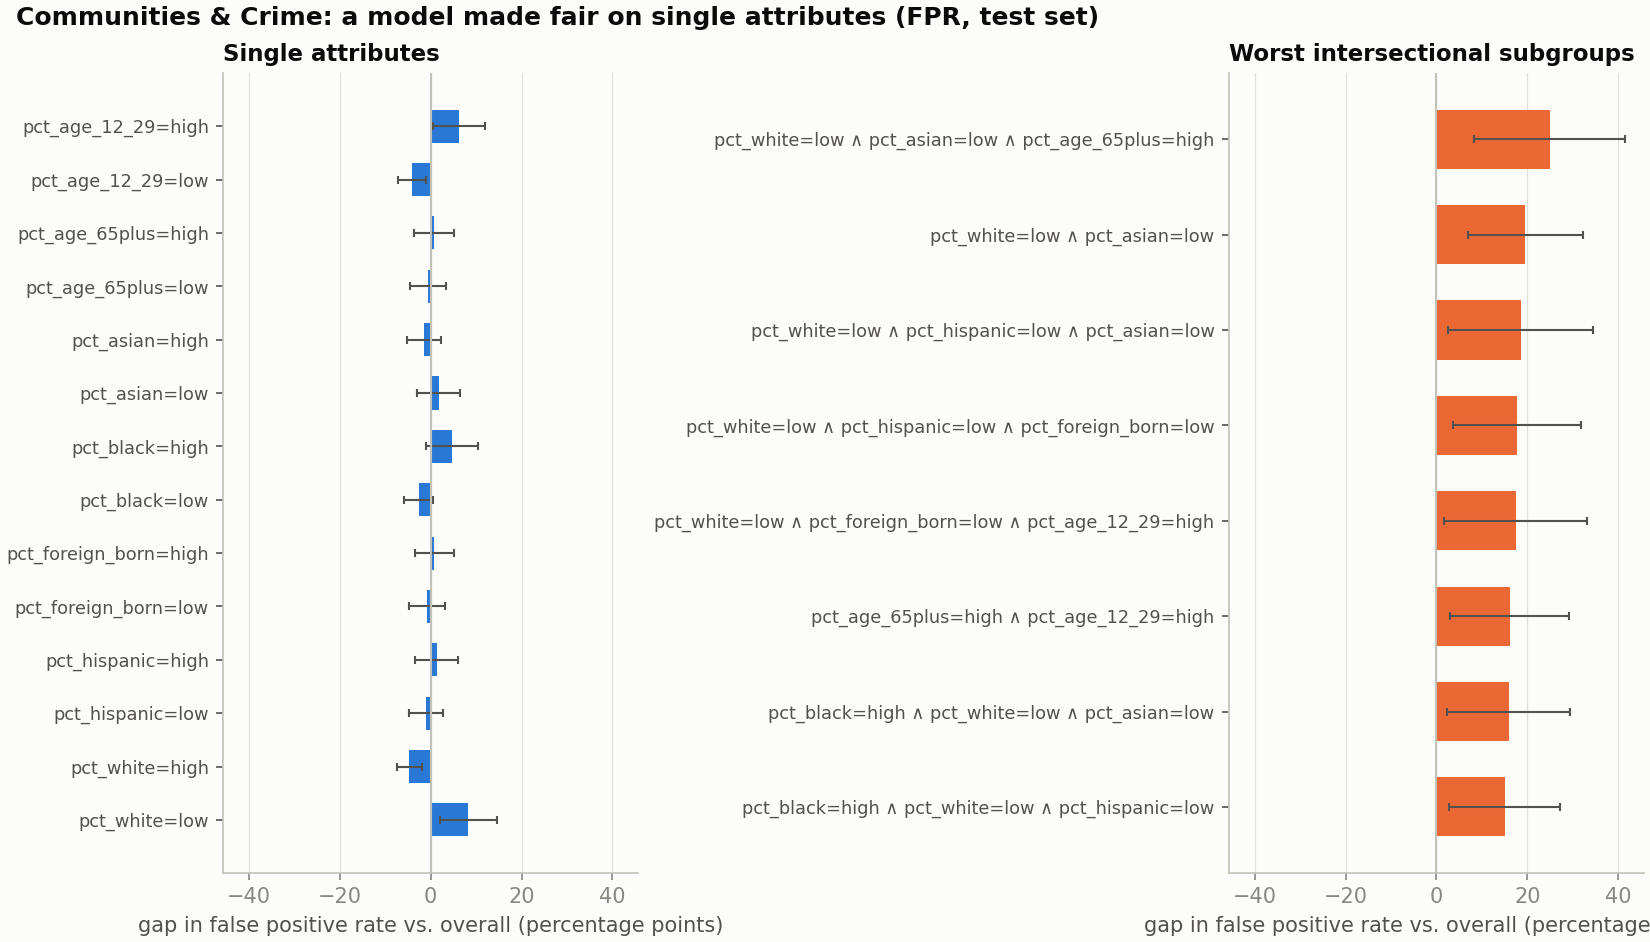

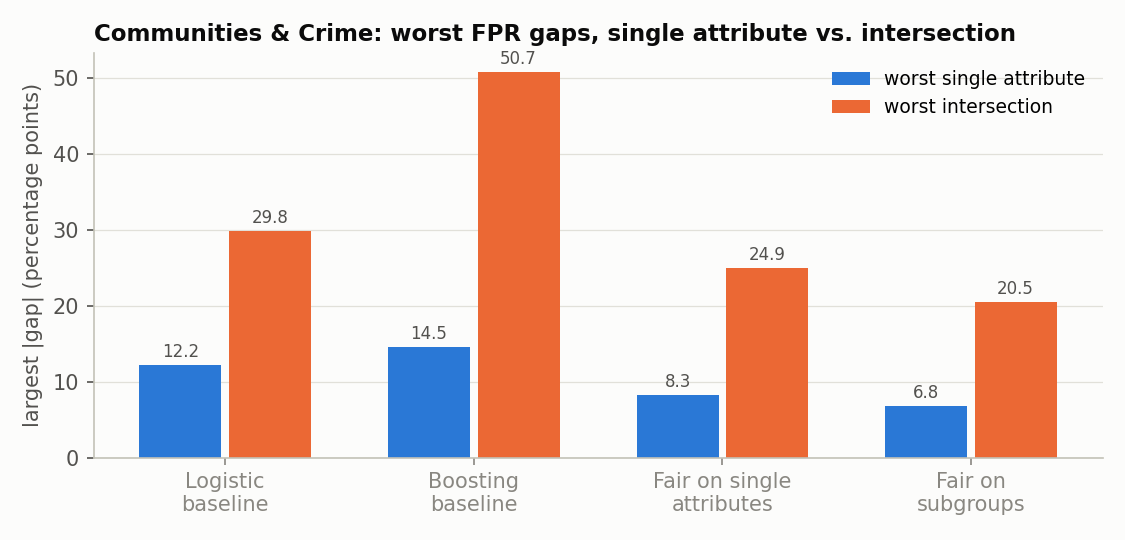

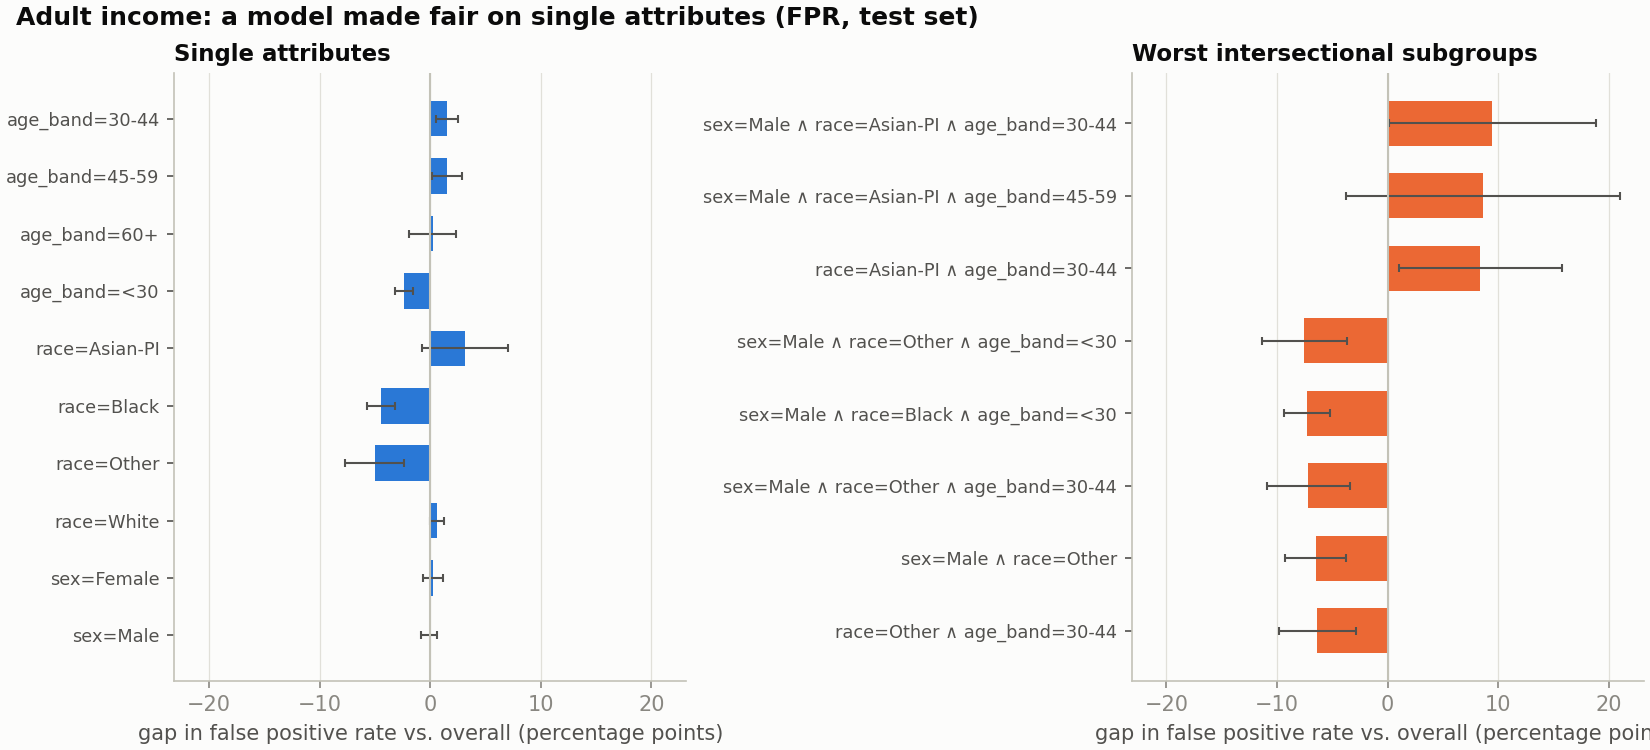

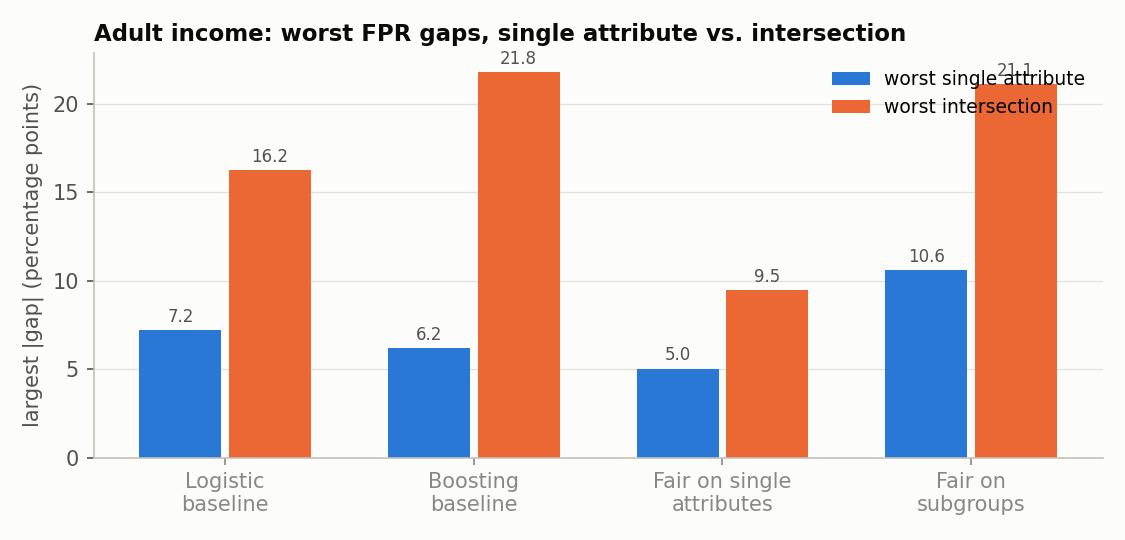

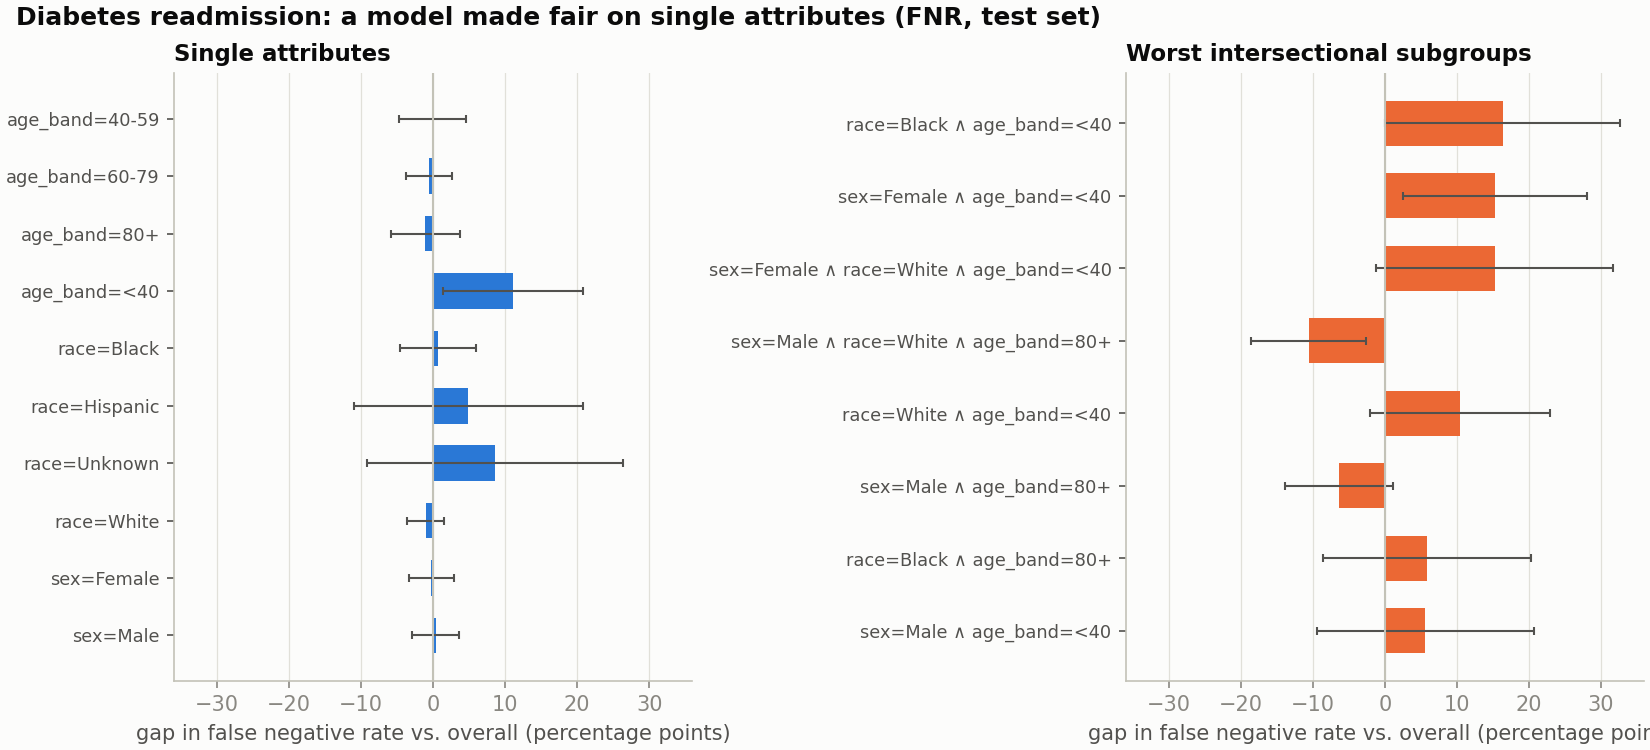

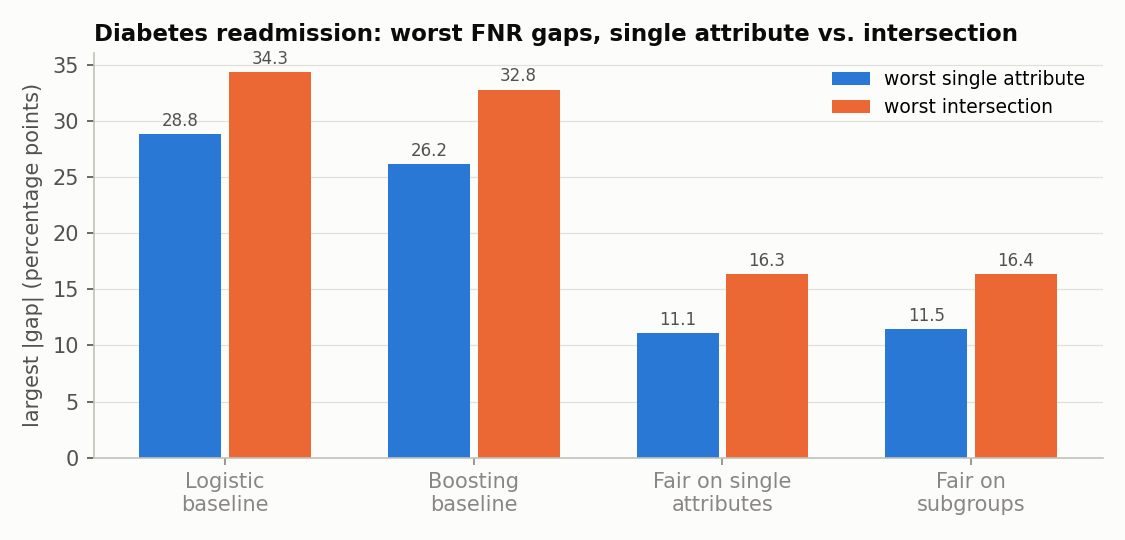

In [4]:
for n in R:
    display(Image(f'../figures/{n}_gerrymandering.png'))
    display(Image(f'../figures/{n}_worst_gaps.png'))

## 4. Accuracy–fairness trade-off

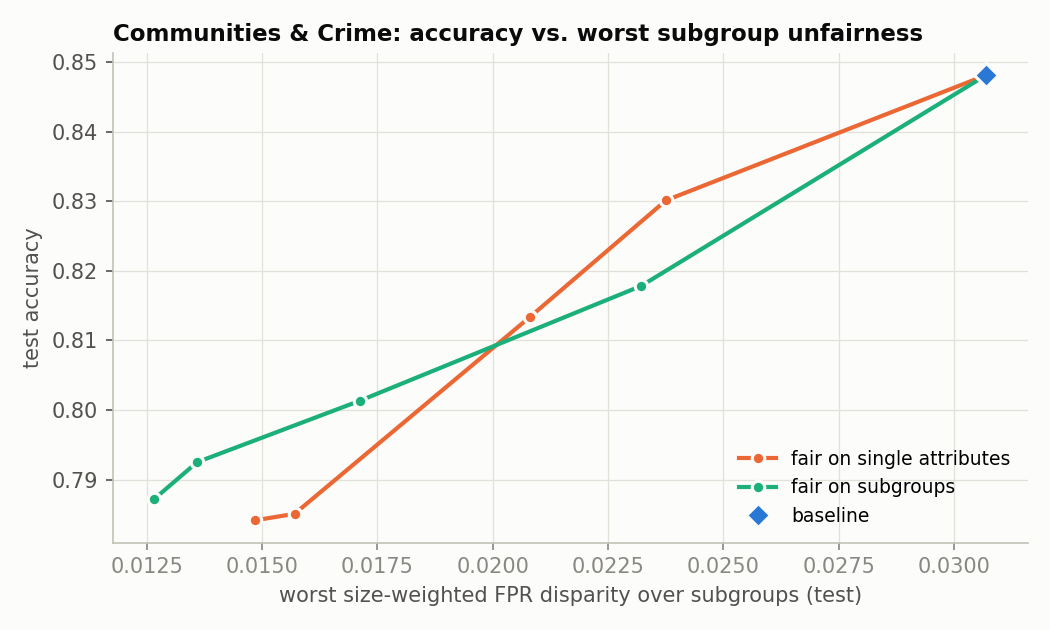

,gamma,accuracy,balanced_accuracy,max_weighted_gap,worst_intersection_gap,worst_single_gap
0,0.0200,0.8481,0.8003,0.0307,0.2981,0.1218
1,0.0100,0.8178,0.7662,0.0232,0.2809,0.0921
2,0.0050,0.8013,0.7465,0.0171,0.2050,0.0679
3,0.0025,0.7925,0.7382,0.0136,0.1579,0.0539
4,0.0010,0.7872,0.7321,0.0127,0.1432,0.0494


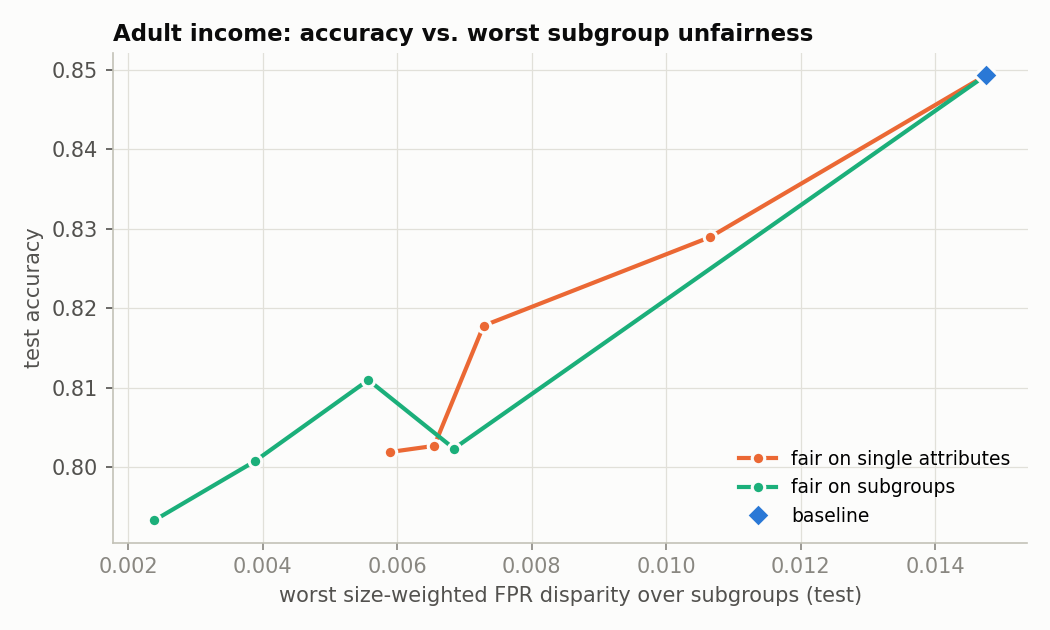

,gamma,accuracy,balanced_accuracy,max_weighted_gap,worst_intersection_gap,worst_single_gap
0,0.0200,0.8493,0.7677,0.0148,0.1622,0.0722
1,0.0100,0.8023,0.7198,0.0068,0.2501,0.1179
2,0.0050,0.8110,0.7218,0.0056,0.2111,0.1057
3,0.0025,0.8007,0.7163,0.0039,0.1506,0.0838
4,0.0010,0.7933,0.7085,0.0024,0.1075,0.0612


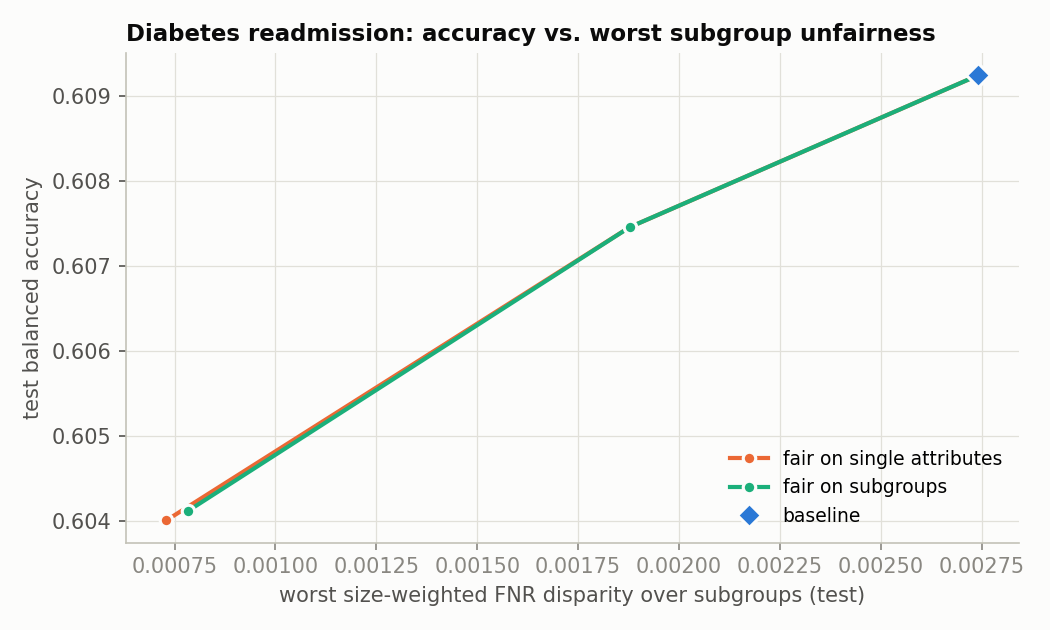

,gamma,accuracy,balanced_accuracy,max_weighted_gap,worst_intersection_gap,worst_single_gap
0,0.0200,0.6782,0.6092,0.0027,0.3434,0.2881
1,0.0100,0.6782,0.6092,0.0027,0.3434,0.2881
2,0.0050,0.6782,0.6092,0.0027,0.3434,0.2881
3,0.0025,0.6777,0.6075,0.0019,0.2940,0.2163
4,0.0010,0.6731,0.6041,0.0008,0.1637,0.1147


In [5]:
for n in R:
    display(Image(f'../figures/{n}_tradeoff.png'))
    display(pd.DataFrame(R[n]['tradeoff']['subgroup_fair']).round(4))

## 5. Paper setting and the reference implementation

Linear-threshold subgroups over the 18 protected attributes used in the authors' GerryFair repository, and the effect of the indexing issue in its cost update (our port; see README).

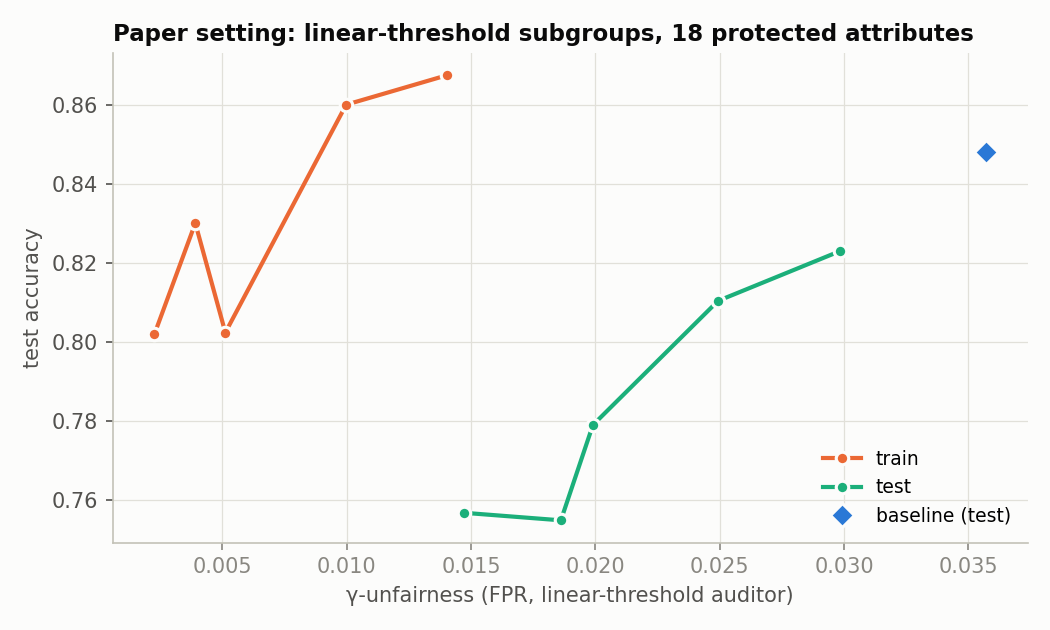

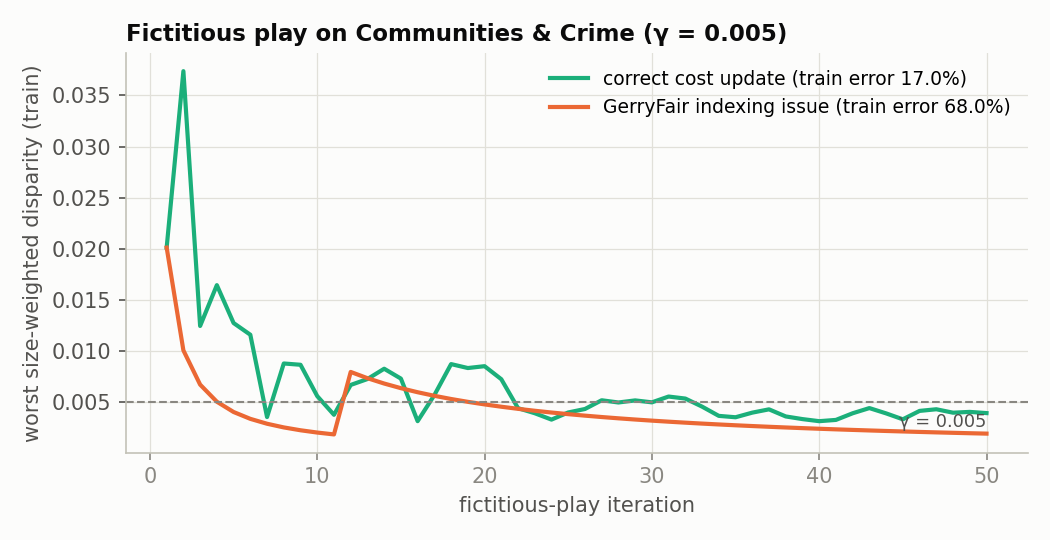

,fixed,with_bug
train_error,0.1699,0.6795
train_unfairness,0.0039,0.0019
test_error,0.2211,0.6797
test_unfairness,0.0199,0.0022


In [6]:
display(Image('../figures/communities_paper_tradeoff.png'))
display(Image('../figures/communities_convergence.png'))
pd.DataFrame({k: {a: b for a, b in v.items() if a != 'history'} for k, v in R['communities']['paper']['bug'].items()}).round(4)